In [1]:

# Data Preparation for House Price Prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
# 1. Load Dataset
df = pd.read_csv("Bengaluru_House_Data.csv")

print("Original Dataset:")
print(df.head())




Original Dataset:
              area_type   availability                  location       size  \
0  Super built-up  Area         19-Dec  Electronic City Phase II      2 BHK   
1            Plot  Area  Ready To Move          Chikka Tirupathi  4 Bedroom   
2        Built-up  Area  Ready To Move               Uttarahalli      3 BHK   
3  Super built-up  Area  Ready To Move        Lingadheeranahalli      3 BHK   
4  Super built-up  Area  Ready To Move                  Kothanur      2 BHK   

   society total_sqft  bath  balcony   price  
0  Coomee        1056   2.0      1.0   39.07  
1  Theanmp       2600   5.0      3.0  120.00  
2      NaN       1440   2.0      3.0   62.00  
3  Soiewre       1521   3.0      1.0   95.00  
4      NaN       1200   2.0      1.0   51.00  


In [3]:
# 2. Select Required Columns
df = df[["total_sqft", "price"]].copy()

# 3. Check Dataset Information
print("\nDataset Information:")
df.info()




Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_sqft  13320 non-null  object 
 1   price       13320 non-null  float64
dtypes: float64(1), object(1)
memory usage: 208.3+ KB


In [4]:
# 4. Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Remove Missing Values
df.dropna(inplace=True)




Missing Values:
total_sqft    0
price         0
dtype: int64


In [5]:
# 6. Convert total_sqft into Numeric Values
def convert_sqft(x):
    try:
        values = str(x).split("-")

        if len(values) == 2:
            return (float(values[0]) + float(values[1])) / 2

        return float(x)

    except (ValueError, TypeError):
        return np.nan

df["total_sqft"] = df["total_sqft"].apply(convert_sqft)



In [6]:
# 7. Remove Invalid Values
df.dropna(inplace=True)

df = df[
    (df["total_sqft"] > 0) &
    (df["price"] > 0)
]



In [7]:
# 8. Check Duplicate Records
print("\nDuplicate Records:")
print(df.duplicated().sum())




Duplicate Records:
3531


In [8]:
# 9. Remove Duplicate Records
df.drop_duplicates(inplace=True)



In [9]:
# 10. Display Cleaned Dataset
print("\nCleaned Dataset:")
print(df.head())

print("\nFinal Dataset Shape:")
print(df.shape)




Cleaned Dataset:
   total_sqft   price
0      1056.0   39.07
1      2600.0  120.00
2      1440.0   62.00
3      1521.0   95.00
4      1200.0   51.00

Final Dataset Shape:
(9743, 2)


In [10]:
# 11. Statistical Summary
print("\nStatistical Summary:")
print(df.describe())




Statistical Summary:
         total_sqft        price
count   9743.000000  9743.000000
mean    1634.576815   119.740848
std     1391.671873   164.459721
min        1.000000     8.000000
25%     1100.000000    50.000000
50%     1330.000000    75.000000
75%     1751.500000   125.000000
max    52272.000000  3600.000000


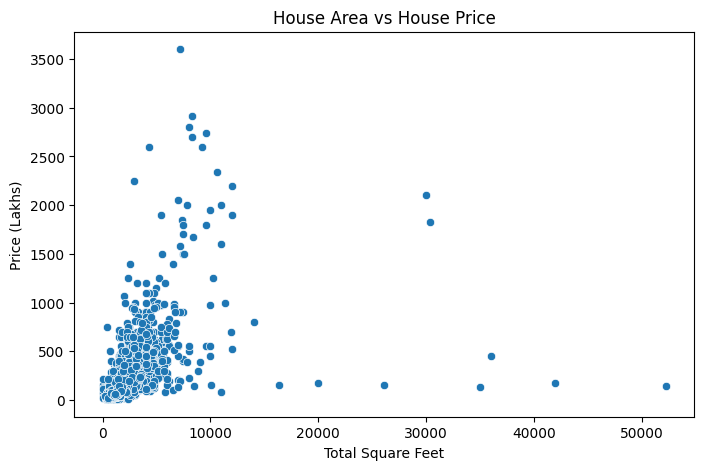

In [11]:
# 12. Visualize Data
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="total_sqft",
    y="price"
)

plt.title("House Area vs House Price")
plt.xlabel("Total Square Feet")
plt.ylabel("Price (Lakhs)")
plt.show()



In [12]:
# 13. Save Cleaned Dataset
df.to_csv("Cleaned_House_Data.csv", index=False)

print("\nCleaned dataset saved successfully!")


Cleaned dataset saved successfully!
